# Predictive Forecasting of Care Load & Placement Demand

## 1. Project Overview

This project uses historical UAC (Unaccompanied Alien Children) program data to forecast the number of children in HHS care and estimate future discharge demand.

The analysis aims to identify potential imbalances between transfers into HHS care and discharges, helping decision-makers anticipate future care demands.

## Project Objectives
- Forecast the number of children in HHS care.
- Estimate the future imbalance between intake and exits.
- Predict short-term discharge demand.
- Provide early warnings for potential capacity stress.
- Compare statistical and machine-learning forecasting approaches.
- Quantify forecast uncertainty.

## 2. Import Libraries and Load Dataset

Import the required Python libraries and load the UAC dataset into a Pandas DataFrame. Inspect the first five records, dataset dimensions, column names, and data types.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the uploaded dataset
file_path = "/content/HHS_Unaccompanied_Alien_Children_Program - HHS_Unaccompanied_Alien_Children_Program.csv"

df = pd.read_csv(file_path)

# Display the first five records
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6,18,11,"2,484",14
1,"December 18, 2025",11,50,6,"2,472",16
2,"December 17, 2025",7,31,11,"2,481",10
3,"December 16, 2025",8,54,15,"2,468",9
4,"December 15, 2025",11,42,9,"2,470",7


Dataset shape: (720, 6)

Column names:
['Date', 'Children apprehended and placed in CBP custody*', 'Children in CBP custody', 'Children transferred out of CBP custody', 'Children in HHS Care', 'Children discharged from HHS Care']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype 
---  ------                                           --------------  ----- 
 0   Date                                             720 non-null    object
 1   Children apprehended and placed in CBP custody*  720 non-null    int64 
 2   Children in CBP custody                          720 non-null    int64 
 3   Children transferred out of CBP custody          720 non-null    int64 
 4   Children in HHS Care                             720 non-null    object
 5   Children discharged from HHS Care                720 non-null    int64 
dtypes: int64(4), object(2)


## 3. Data Cleaning and Date Conversion

Convert the Date column to datetime format and convert Children in HHS Care to numeric format. Sort the dataset by date in ascending order and check for missing values and duplicate dates.

In [2]:
# Convert Date to datetime format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%B %d, %Y",
    errors="coerce"
)

# Convert HHS care values to numeric
df["Children in HHS Care"] = pd.to_numeric(
    df["Children in HHS Care"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Sort dataset by date
df = df.sort_values("Date").reset_index(drop=True)

# Check data types
print("Updated data types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate dates
print("\nDuplicate dates:", df["Date"].duplicated().sum())

# Display first five records
display(df.head())

Updated data types:
Date                                               datetime64[ns]
Children apprehended and placed in CBP custody*             int64
Children in CBP custody                                     int64
Children transferred out of CBP custody                     int64
Children in HHS Care                                        int64
Children discharged from HHS Care                           int64
dtype: object

Missing values:
Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

Duplicate dates: 0


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33,53,34,6566,436
1,2023-01-22,32,49,39,7122,227
2,2023-01-23,32,50,39,7280,181
3,2023-01-24,47,42,47,7433,175
4,2023-01-25,20,22,41,7538,180


## 4. Check Daily Date Continuity

Check whether the dataset contains observations for every calendar day between the first and last reporting dates. Identify missing dates to prepare the daily time series for forecasting.

In [3]:
# Set Date as the DataFrame index
df = df.set_index("Date").sort_index()

# Generate a complete daily date range
full_date_range = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

# Identify missing calendar dates
missing_dates = full_date_range.difference(df.index)

print("First reporting date:", df.index.min())
print("Last reporting date:", df.index.max())
print("Existing records:", len(df))
print("Expected daily records:", len(full_date_range))
print("Missing calendar dates:", len(missing_dates))

# Display the first 10 missing dates
print("\nFirst 10 missing dates:")
print(missing_dates[:10])

First reporting date: 2023-01-12 00:00:00
Last reporting date: 2025-12-21 00:00:00
Existing records: 720
Expected daily records: 1075
Missing calendar dates: 355

First 10 missing dates:
DatetimeIndex(['2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16',
               '2023-01-17', '2023-01-18', '2023-01-19', '2023-01-20',
               '2023-01-21', '2023-01-26'],
              dtype='datetime64[ns]', freq=None)


## 5. Handle Missing Calendar Dates

Create a continuous daily time series by reindexing the dataset to include every calendar day. Apply time-based interpolation to estimate missing values, as permitted by the project methodology.

In [4]:
# Create a continuous daily time series
daily_df = df.reindex(full_date_range)
daily_df.index.name = "Date"

# Count missing values before interpolation
print("Missing values before interpolation:")
print(daily_df.isnull().sum())

# Apply time-based interpolation
daily_df = daily_df.interpolate(method="time")

# Check missing values after interpolation
print("\nMissing values after interpolation:")
print(daily_df.isnull().sum())

# Display final dataset information
print("\nFinal dataset shape:", daily_df.shape)

# Display first five records
display(daily_df.head())

# Display last five records
display(daily_df.tail())

Missing values before interpolation:
Children apprehended and placed in CBP custody*    355
Children in CBP custody                            355
Children transferred out of CBP custody            355
Children in HHS Care                               355
Children discharged from HHS Care                  355
dtype: int64

Missing values after interpolation:
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

Final dataset shape: (1075, 5)


,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
Date,,,,,
2023-01-12,33.0,53.0,34.0,6566.0,436.0
2023-01-13,32.9,52.6,34.5,6621.6,415.1
2023-01-14,32.8,52.2,35.0,6677.2,394.2
2023-01-15,32.7,51.8,35.5,6732.8,373.3
2023-01-16,32.6,51.4,36.0,6788.4,352.4


,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
Date,,,,,
2025-12-17,7.000000,31.000000,11.000000,2481.0,10.000000
2025-12-18,11.000000,50.000000,6.000000,2472.0,16.000000
2025-12-19,9.333333,39.333333,7.666667,2476.0,15.333333
2025-12-20,7.666667,28.666667,9.333333,2480.0,14.666667
2025-12-21,6.000000,18.000000,11.000000,2484.0,14.000000


## 6. Time-Series Decomposition

Decompose the daily number of children in HHS care into trend, seasonal, and residual components to understand long-term movements, recurring patterns, and unexplained variation.

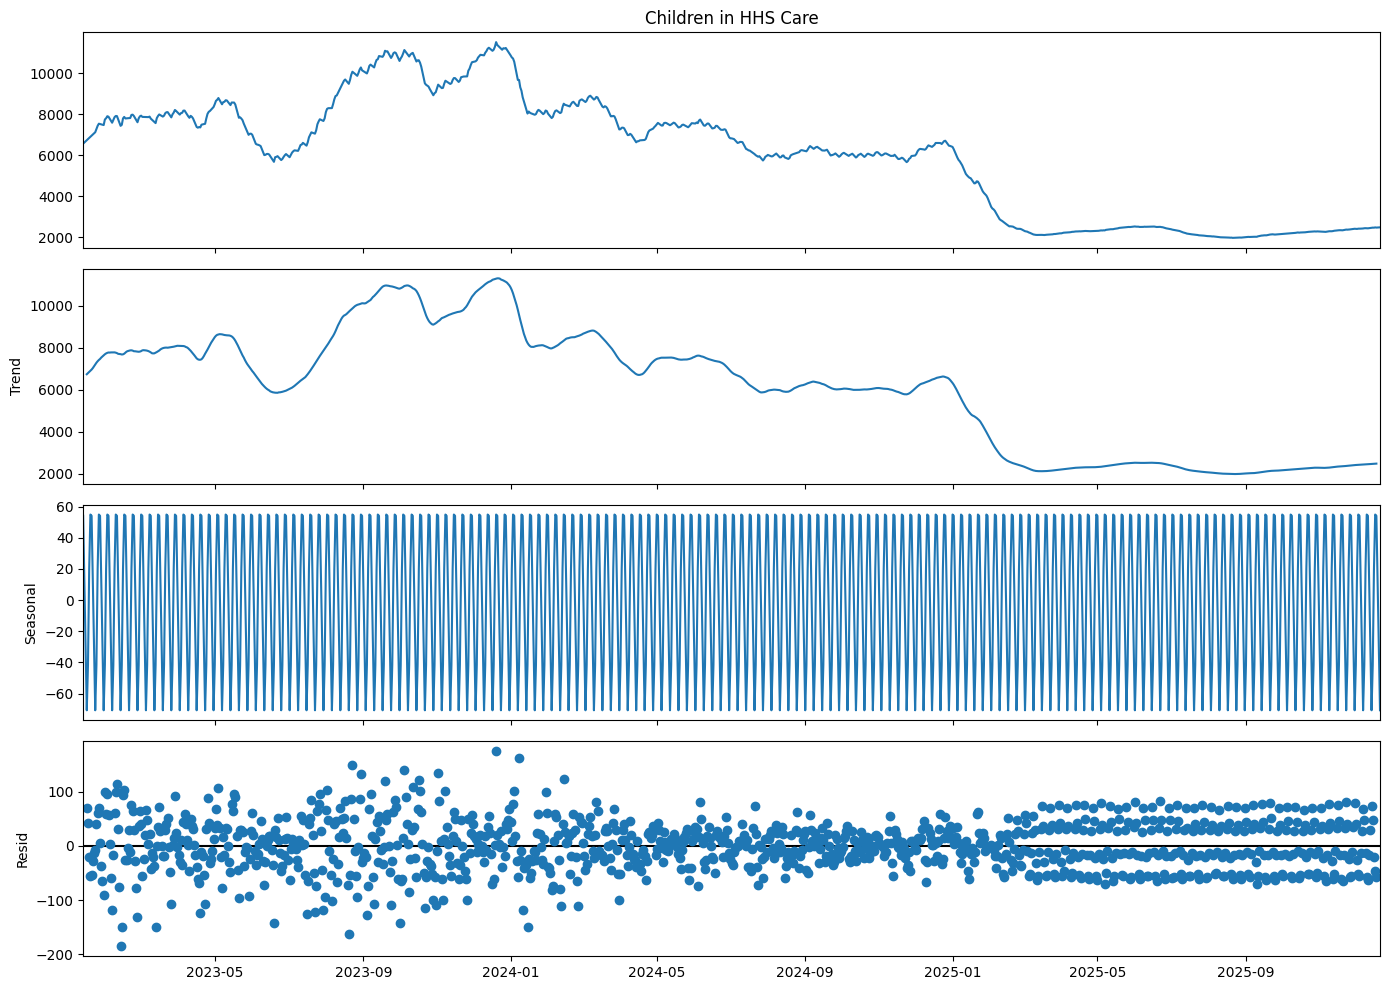

In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Select the HHS care time series
hhs_series = daily_df["Children in HHS Care"]

# Decompose the series using a 7-day seasonal period
decomposition = seasonal_decompose(
    hhs_series,
    model="additive",
    period=7
)

# Plot the decomposition components
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

## 7. Feature Engineering

Create lag features, rolling averages, rolling variance, flow-based signals, and calendar features for forecasting.

These features will help the statistical and machine-learning models learn from past care loads, recent changes, transfers, discharges, and calendar patterns.

In [6]:
# Create a copy for feature engineering
model_df = daily_df.copy()

# Target: future HHS care load
model_df["HHS_Care_Load"] = model_df["Children in HHS Care"]

# Lag features
for lag in [1, 7, 14]:
    model_df[f"HHS_Lag_{lag}"] = (
        model_df["HHS_Care_Load"].shift(lag)
    )

# Rolling averages and variance
for window in [7, 14]:
    model_df[f"Rolling_Mean_{window}"] = (
        model_df["HHS_Care_Load"]
        .shift(1)
        .rolling(window=window)
        .mean()
    )

    model_df[f"Rolling_Variance_{window}"] = (
        model_df["HHS_Care_Load"]
        .shift(1)
        .rolling(window=window)
        .var()
    )

# Flow-based pressure indicator
model_df["Net_Pressure"] = (
    model_df["Children transferred out of CBP custody"]
    - model_df["Children discharged from HHS Care"]
)

# Calendar features
model_df["Day_of_Week"] = model_df.index.dayofweek
model_df["Month"] = model_df.index.month

# Display engineered features
display(model_df.head(20))

print("Dataset shape:", model_df.shape)
print("\nMissing values in engineered features:")
print(model_df.isnull().sum())

,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,HHS_Care_Load,HHS_Lag_1,HHS_Lag_7,HHS_Lag_14,Rolling_Mean_7,Rolling_Variance_7,Rolling_Mean_14,Rolling_Variance_14,Net_Pressure,Day_of_Week,Month
Date,,,,,,,,,,,,,,,,
2023-01-12,33.00,53.00,34.0,6566.0,436.00,6566.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-402.00,3,1
2023-01-13,32.90,52.60,34.5,6621.6,415.10,6621.6,6566.0,NaN,NaN,NaN,NaN,NaN,NaN,-380.60,4,1
2023-01-14,32.80,52.20,35.0,6677.2,394.20,6677.2,6621.6,NaN,NaN,NaN,NaN,NaN,NaN,-359.20,5,1
2023-01-15,32.70,51.80,35.5,6732.8,373.30,6732.8,6677.2,NaN,NaN,NaN,NaN,NaN,NaN,-337.80,6,1
2023-01-16,32.60,51.40,36.0,6788.4,352.40,6788.4,6732.8,NaN,NaN,NaN,NaN,NaN,NaN,-316.40,0,1
2023-01-17,32.50,51.00,36.5,6844.0,331.50,6844.0,6788.4,NaN,NaN,NaN,NaN,NaN,NaN,-295.00,1,1
2023-01-18,32.40,50.60,37.0,6899.6,310.60,6899.6,6844.0,NaN,NaN,NaN,NaN,NaN,NaN,-273.60,2,1
2023-01-19,32.30,50.20,37.5,6955.2,289.70,6955.2,6899.6,6566.0,NaN,6732.800000,14426.346667,NaN,NaN,-252.20,3,1
2023-01-20,32.20,49.80,38.0,7010.8,268.80,7010.8,6955.2,6621.6,NaN,6788.400000,14426.346667,NaN,NaN,-230.80,4,1


Dataset shape: (1075, 16)

Missing values in engineered features:
Children apprehended and placed in CBP custody*     0
Children in CBP custody                             0
Children transferred out of CBP custody             0
Children in HHS Care                                0
Children discharged from HHS Care                   0
HHS_Care_Load                                       0
HHS_Lag_1                                           1
HHS_Lag_7                                           7
HHS_Lag_14                                         14
Rolling_Mean_7                                      7
Rolling_Variance_7                                  7
Rolling_Mean_14                                    14
Rolling_Variance_14                                14
Net_Pressure                                        0
Day_of_Week                                         0
Month                                               0
dtype: int64


## 8. Prepare Data for Forecasting

Remove rows with missing lag and rolling features, then split the dataset chronologically into training and testing sets. This avoids random sampling and follows the project's time-based validation requirement.

In [7]:
# Remove rows with missing engineered features
model_df_clean = model_df.dropna().copy()

# Define features and target
feature_cols = [
    "HHS_Lag_1",
    "HHS_Lag_7",
    "HHS_Lag_14",
    "Rolling_Mean_7",
    "Rolling_Variance_7",
    "Rolling_Mean_14",
    "Rolling_Variance_14",
    "Net_Pressure",
    "Day_of_Week",
    "Month"
]

X = model_df_clean[feature_cols]
y = model_df_clean["HHS_Care_Load"]

# Chronological 80/20 train-test split
split_index = int(len(model_df_clean) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display split information
print("Total usable records:", len(model_df_clean))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Total usable records: 1061
Training records: 848
Testing records: 213

Training period:
2023-01-26 00:00:00 to 2025-05-22 00:00:00

Testing period:
2025-05-23 00:00:00 to 2025-12-21 00:00:00


## 9. Baseline Forecasting Models

Establish baseline forecasting performance using a naïve persistence model and a moving average model. Evaluate both models on the test period using MAE, RMSE, and MAPE.

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Naïve persistence: predict the previous day's HHS care load
naive_predictions = X_test["HHS_Lag_1"]

# Moving average: use the previous 7-day average
moving_avg_predictions = X_test["Rolling_Mean_7"]

# Evaluation function
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Avoid division by zero in MAPE
    y_true_array = np.asarray(y_true)
    y_pred_array = np.asarray(y_pred)
    nonzero_mask = y_true_array != 0

    mape = (
        np.mean(
            np.abs(
                (y_true_array[nonzero_mask]
                 - y_pred_array[nonzero_mask])
                / y_true_array[nonzero_mask]
            )
        ) * 100
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }

# Evaluate baseline models
baseline_results = pd.DataFrame([
    evaluate_model(y_test, naive_predictions, "Naive Persistence"),
    evaluate_model(y_test, moving_avg_predictions, "Moving Average (7-day)")
])

display(baseline_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,6.65,8.25,0.30
1,Moving Average (7-day),21.56,26.58,0.96


## 10. Statistical Forecasting — ARIMA

Fit an ARIMA model using the training time series and generate forecasts for the test period. Evaluate the forecasts using MAE, RMSE, and MAPE.

In [9]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the original HHS care-load target
y_train_ts = y_train.astype(float)
y_test_ts = y_test.astype(float)

# Fit ARIMA model
arima_model = ARIMA(
    y_train_ts,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

# Forecast the entire test period
arima_predictions = arima_fit.forecast(
    steps=len(y_test_ts)
)

# Align forecast dates with test dates
arima_predictions.index = y_test_ts.index

# Evaluate ARIMA
arima_results = pd.DataFrame([
    evaluate_model(
        y_test_ts,
        arima_predictions,
        "ARIMA(1,1,1)"
    )
])

display(arima_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,"ARIMA(1,1,1)",233.32,286.88,11.0


## 11. Statistical Forecasting — Exponential Smoothing

Fit an exponential smoothing model to the training time series and forecast HHS care load over the test period. Evaluate its performance using MAE, RMSE, and MAPE.

In [10]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Fit exponential smoothing model
es_model = ExponentialSmoothing(
    y_train_ts,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

es_fit = es_model.fit()

# Forecast the test period
es_predictions = es_fit.forecast(
    steps=len(y_test_ts)
)

# Align forecast dates with test dates
es_predictions.index = y_test_ts.index

# Evaluate the model
es_results = pd.DataFrame([
    evaluate_model(
        y_test_ts,
        es_predictions,
        "Exponential Smoothing"
    )
])

display(es_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Exponential Smoothing,848.53,942.65,38.51


## 12. Machine Learning Forecasting — Random Forest

Train a Random Forest Regressor using the engineered lag, rolling, flow-based, and calendar features. Generate predictions for the test period and evaluate performance using MAE, RMSE, and MAPE.

In [11]:
from sklearn.ensemble import RandomForestRegressor

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = pd.Series(
    rf_model.predict(X_test),
    index=y_test.index
)

# Evaluate the model
rf_results = pd.DataFrame([
    evaluate_model(
        y_test,
        rf_predictions,
        "Random Forest"
    )
])

display(rf_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Random Forest,38.98,61.02,1.85


## 13. Machine Learning Forecasting — Gradient Boosting

Train a Gradient Boosting Regressor using the engineered features. Evaluate its predictions on the test period using MAE, RMSE, and MAPE.

In [12]:
from sklearn.ensemble import GradientBoostingRegressor

# Train Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

# Generate test predictions
gb_predictions = pd.Series(
    gb_model.predict(X_test),
    index=y_test.index
)

# Evaluate the model
gb_results = pd.DataFrame([
    evaluate_model(
        y_test,
        gb_predictions,
        "Gradient Boosting"
    )
])

display(gb_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Gradient Boosting,56.11,78.95,2.66


## 14. Statistical Forecasting — SARIMA

Fit a Seasonal ARIMA (SARIMA) model to capture both temporal dependencies and weekly seasonality in the daily HHS care-load series. Generate forecasts over the test period and evaluate the results using MAE, RMSE, and MAPE.

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Fit SARIMA model with weekly seasonality
sarima_model = SARIMAX(
    y_train_ts,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

# Forecast the test period
sarima_predictions = sarima_fit.forecast(
    steps=len(y_test_ts)
)

# Align forecast dates
sarima_predictions.index = y_test_ts.index

# Evaluate the model
sarima_results = pd.DataFrame([
    evaluate_model(
        y_test_ts,
        sarima_predictions,
        "SARIMA(1,1,1)(1,1,1,7)"
    )
])

display(sarima_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,"SARIMA(1,1,1)(1,1,1,7)",585.01,782.71,25.47


## 15. Model Comparison

Compare the baseline, statistical, and machine-learning forecasting models using MAE, RMSE, and MAPE. These metrics will help identify which model performs best on the test dataset.

In [14]:
# Combine results from all seven forecasting models

all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        es_results,
        rf_results,
        gb_results,
        sarima_results
    ],
    ignore_index=True
)

# Sort models by MAE, from lowest to highest
all_results = all_results.sort_values(
    by="MAE"
).reset_index(drop=True)

# Display comparison table
display(all_results.round(2))

# Identify the model with the lowest MAE
best_model = all_results.loc[
    all_results["MAE"].idxmin()
]

print("\nBest model based on MAE:")
print(best_model)

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,6.65,8.25,0.30
1,Moving Average (7-day),21.56,26.58,0.96
2,Random Forest,38.98,61.02,1.85
3,Gradient Boosting,56.11,78.95,2.66
4,"ARIMA(1,1,1)",233.32,286.88,11.00
5,"SARIMA(1,1,1)(1,1,1,7)",585.01,782.71,25.47
6,Exponential Smoothing,848.53,942.65,38.51



Best model based on MAE:
Model       Naive Persistence
MAE                  6.652582
RMSE                 8.250273
MAPE (%)              0.29521
Name: 0, dtype: object


## 16. Walk-Forward Validation

Evaluate the Naïve Persistence baseline using walk-forward validation. At each step, predict the next day's HHS care load using the previous day's observed value. Calculate MAE, RMSE, and MAPE across the validation period.

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Walk-forward predictions for the Naïve Persistence baseline
actual_values = y_test_ts.copy()
walk_forward_predictions = actual_values.shift(1)

# Use the last training observation for the first test prediction
walk_forward_predictions.iloc[0] = y_train_ts.iloc[-1]

# Evaluate predictions
valid_mask = walk_forward_predictions.notna()

wf_actual = actual_values[valid_mask]
wf_predicted = walk_forward_predictions[valid_mask]

walk_forward_results = pd.DataFrame([
    evaluate_model(
        wf_actual,
        wf_predicted,
        "Naive Persistence - Walk-Forward"
    )
])

display(walk_forward_results.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence - Walk-Forward,6.65,8.25,0.3


## 17. Multi-Horizon Evaluation

Evaluate the Naïve Persistence baseline at 1-day, 7-day, and 14-day forecast horizons. Compare the forecast errors to understand how accuracy changes as the prediction horizon increases.

In [16]:
# Evaluate persistence forecasts at multiple horizons

horizon_results = []

for horizon in [1, 7, 14]:
    # Predict using the value observed horizon days earlier
    predictions = y_test_ts.shift(horizon)

    # Use actual training observations for the initial test dates
    for i in range(min(horizon, len(y_test_ts))):
        predictions.iloc[i] = (
            y_train_ts.iloc[-(horizon - i)]
            if horizon - i <= len(y_train_ts)
            else np.nan
        )

    valid = predictions.notna()

    result = evaluate_model(
        y_test_ts[valid],
        predictions[valid],
        f"{horizon}-Day Horizon"
    )

    result["Horizon (days)"] = horizon
    horizon_results.append(result)

horizon_results_df = pd.DataFrame(horizon_results)

display(
    horizon_results_df[
        ["Horizon (days)", "Model", "MAE", "RMSE", "MAPE (%)"]
    ].round(2)
)

,Horizon (days),Model,MAE,RMSE,MAPE (%)
0,1,1-Day Horizon,6.65,8.25,0.30
1,7,7-Day Horizon,37.57,45.89,1.68
2,14,14-Day Horizon,72.56,88.20,3.26


## 18. Forecast Uncertainty and Confidence Intervals

Estimate uncertainty around the Naïve Persistence forecast using the distribution of historical one-day forecast errors. Visualize the forecast and its approximate 95% prediction interval.

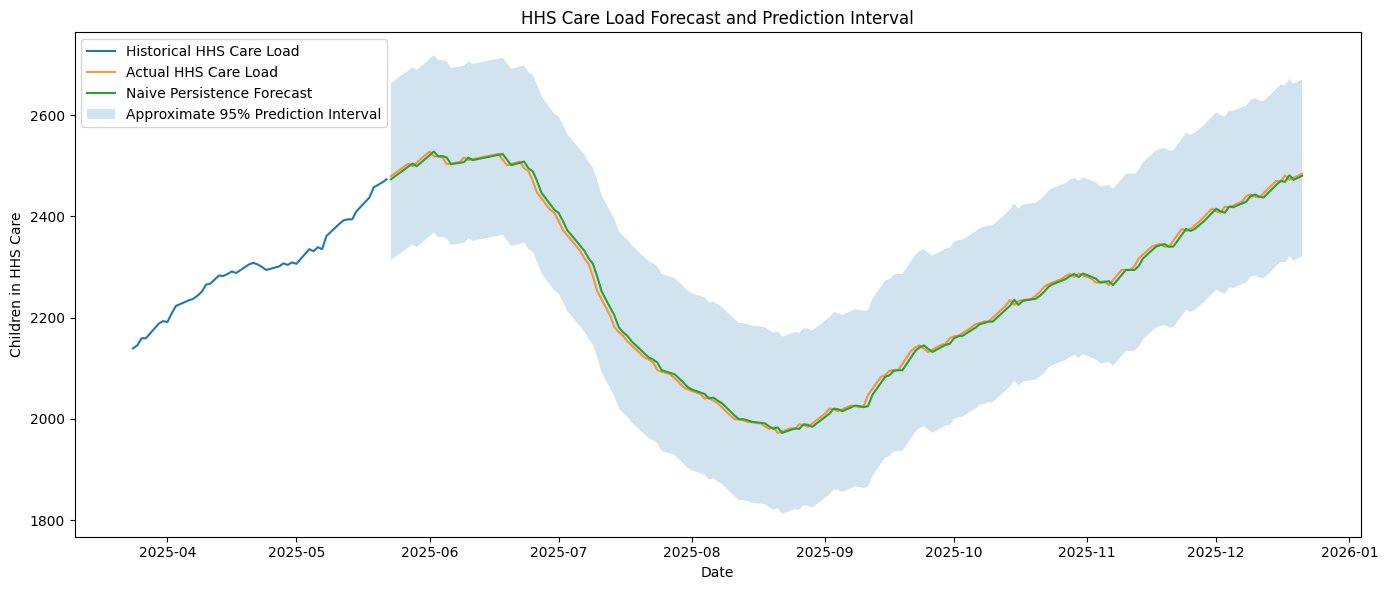

In [17]:
# Calculate historical one-day forecast errors
historical_errors = (
    y_train_ts - y_train_ts.shift(1)
).dropna()

# Estimate the 95% error interval
error_lower = historical_errors.quantile(0.025)
error_upper = historical_errors.quantile(0.975)

# Plot the last 60 training days and the test-period forecast
forecast_dates = y_test_ts.index
forecast_values = naive_predictions

plt.figure(figsize=(14, 6))

plt.plot(
    y_train_ts.index[-60:],
    y_train_ts.iloc[-60:],
    label="Historical HHS Care Load"
)

plt.plot(
    forecast_dates,
    y_test_ts,
    label="Actual HHS Care Load",
    alpha=0.8
)

plt.plot(
    forecast_dates,
    forecast_values,
    label="Naive Persistence Forecast"
)

plt.fill_between(
    forecast_dates,
    forecast_values + error_lower,
    forecast_values + error_upper,
    alpha=0.2,
    label="Approximate 95% Prediction Interval"
)

plt.title("HHS Care Load Forecast and Prediction Interval")
plt.xlabel("Date")
plt.ylabel("Children in HHS Care")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Key Performance Indicators (KPIs)

Calculate Forecast Accuracy (%) from the Naïve Persistence model's test-set MAPE to summarize its relative forecasting accuracy.

In [18]:
# Calculate forecast accuracy from test-set MAPE
naive_mape = baseline_results.loc[
    baseline_results["Model"] == "Naive Persistence",
    "MAPE (%)"
].iloc[0]

forecast_accuracy = 100 - naive_mape

print(f"Naive Persistence MAPE: {naive_mape:.2f}%")
print(f"Forecast Accuracy: {forecast_accuracy:.2f}%")

Naive Persistence MAPE: 0.30%
Forecast Accuracy: 99.70%


## 20. Surge Lead Time

Identify sharp increases in daily HHS care load using the change from the previous day. This provides an initial view of potential surges in care demand.

In [19]:
# Calculate daily changes in HHS care load
daily_df["Daily_Care_Change"] = (
    daily_df["Children in HHS Care"].diff()
)

# Calculate the 95th percentile of positive daily changes
positive_changes = daily_df.loc[
    daily_df["Daily_Care_Change"] > 0,
    "Daily_Care_Change"
]

surge_threshold = positive_changes.quantile(0.95)

# Identify sharp increases
surge_events = daily_df[
    daily_df["Daily_Care_Change"] > surge_threshold
][["Children in HHS Care", "Daily_Care_Change"]]

print(f"Surge threshold: {surge_threshold:.2f} children")
print("Number of detected surge events:", len(surge_events))

print("\nFirst 10 detected surge events:")
display(surge_events.head(10))

Surge threshold: 170.00 children
Number of detected surge events: 26

First 10 detected surge events:


,Children in HHS Care,Daily_Care_Change
Date,,
2023-01-30,7743.0,271.0
2023-02-14,7794.0,311.0
2023-02-27,7800.0,191.0
2023-03-14,7810.0,243.0
2023-04-24,7796.0,262.0
2023-04-25,8017.0,221.0
2023-06-20,5904.0,225.0
2023-07-18,6874.0,242.0
2023-07-25,7510.0,290.0


## 21. Capacity Breach Probability

Assess the potential risk of exceeding HHS care capacity. A capacity threshold must be defined before calculating breach probability. Since the provided dataset does not specify this threshold, request it as an input rather than assuming a value.

In [20]:
# Enter the official HHS care capacity threshold when available
capacity_threshold = None

if capacity_threshold is None:
    print(
        "Capacity breach probability cannot yet be calculated. "
        "Please provide the approved HHS care capacity threshold."
    )
else:
    breach_days = (
        daily_df["Children in HHS Care"] > capacity_threshold
    ).sum()

    total_days = len(daily_df)

    breach_probability = breach_days / total_days * 100

    print("Capacity threshold:", capacity_threshold)
    print("Days above capacity:", breach_days)
    print(f"Historical breach rate: {breach_probability:.2f}%")

Capacity breach probability cannot yet be calculated. Please provide the approved HHS care capacity threshold.


## 22. Forecast Stability Index

Assess forecast stability by examining the variation in absolute errors from the Naïve Persistence model over the test period. Lower variation indicates more consistent errors over time.

In [21]:
# Calculate absolute errors for the Naïve Persistence model
absolute_errors = np.abs(
    y_test_ts.to_numpy()
    - naive_predictions.to_numpy()
)

# Calculate error variability
mean_absolute_error_value = absolute_errors.mean()
std_absolute_error = absolute_errors.std()

# Calculate a preliminary stability score
if mean_absolute_error_value != 0:
    forecast_stability_score = (
        1 - std_absolute_error / mean_absolute_error_value
    ) * 100
else:
    forecast_stability_score = np.nan

print(f"Mean absolute error: {mean_absolute_error_value:.2f}")
print(f"Standard deviation of absolute errors: {std_absolute_error:.2f}")
print(f"Preliminary stability score: {forecast_stability_score:.2f}")

Mean absolute error: 6.65
Standard deviation of absolute errors: 4.88
Preliminary stability score: 26.65


## 23. Prepare Model Results for the Dashboard

Combine the evaluation results from the baseline, statistical, and machine-learning models into a single table for use in the Streamlit model-comparison panel.

In [22]:
# Combine forecasting model evaluation results
dashboard_model_results = pd.concat(
    [
        baseline_results,
        arima_results,
        es_results,
        rf_results,
        gb_results,
        sarima_results
    ],
    ignore_index=True
)

# Sort by MAE
dashboard_model_results = (
    dashboard_model_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

# Display the results
display(dashboard_model_results.round(2))

# Save results for the dashboard
dashboard_model_results.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully.")

,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,6.65,8.25,0.30
1,Moving Average (7-day),21.56,26.58,0.96
2,Random Forest,38.98,61.02,1.85
3,Gradient Boosting,56.11,78.95,2.66
4,"ARIMA(1,1,1)",233.32,286.88,11.00
5,"SARIMA(1,1,1)(1,1,1,7)",585.01,782.71,25.47
6,Exponential Smoothing,848.53,942.65,38.51


Model comparison results saved successfully.


## 24. Export Prepared Dataset

Export the cleaned daily time series for use in the Streamlit dashboard. The exported dataset contains the historical observations required for forecasting HHS care load and discharge demand.

In [23]:
# Export the cleaned daily time series
export_df = daily_df.copy()

export_df.index.name = "Date"
export_df.to_csv("uac_daily_cleaned.csv", index=True)

# Download the dataset
from google.colab import files

files.download("uac_daily_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 25. Export Model Comparison Results

Export the forecasting model evaluation results as a CSV file for use in the Streamlit dashboard.

In [24]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 26. Final Model Validation

Validate the forecasting models using time-based testing, walk-forward validation, and 1-day, 7-day, and 14-day forecast horizons. Compare MAE, RMSE, and MAPE to assess model performance.


In [25]:

print("Available model results:")

for name in [
    "model_df",
    "comparison_results",
    "baseline_results",
    "arima_results",
    "es_results",
    "rf_results",
    "gb_results",
    "sarima_results",
    "walk_forward_results",
    "horizon_results"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")


Available model results:
model_df: Available
comparison_results: Not available
baseline_results: Available
arima_results: Available
es_results: Available
rf_results: Available
gb_results: Available
sarima_results: Available
walk_forward_results: Available
horizon_results: Available


In [26]:

import pandas as pd

# Combine the existing model evaluation results
all_results = pd.concat(
    [
        baseline_results,
        arima_results,
        es_results,
        rf_results,
        gb_results,
        sarima_results
    ],
    ignore_index=True
)

# Display the combined comparison
display(all_results.round(2))

print("\nBest model based on MAE:")
display(all_results.loc[[all_results["MAE"].idxmin()]].round(2))


,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,6.65,8.25,0.30
1,Moving Average (7-day),21.56,26.58,0.96
2,"ARIMA(1,1,1)",233.32,286.88,11.00
3,Exponential Smoothing,848.53,942.65,38.51
4,Random Forest,38.98,61.02,1.85
5,Gradient Boosting,56.11,78.95,2.66
6,"SARIMA(1,1,1)(1,1,1,7)",585.01,782.71,25.47



Best model based on MAE:


,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence,6.65,8.25,0.3


In [28]:

import pandas as pd

print("Multi-Horizon Forecast Evaluation")

horizon_df = pd.DataFrame(horizon_results)
display(horizon_df.round(2))

print("\nWalk-Forward Validation Results")

display(pd.DataFrame(walk_forward_results).round(2))


Multi-Horizon Forecast Evaluation


,Model,MAE,RMSE,MAPE (%),Horizon (days)
0,1-Day Horizon,6.65,8.25,0.30,1
1,7-Day Horizon,37.57,45.89,1.68,7
2,14-Day Horizon,72.56,88.20,3.26,14



Walk-Forward Validation Results


,Model,MAE,RMSE,MAPE (%)
0,Naive Persistence - Walk-Forward,6.65,8.25,0.3



## 30. Forecast Output and Export Validation

Verify that the forecast results and model comparison files are available for use in the Streamlit dashboard and final project deliverables.


In [29]:

import os

print("Current working directory:", os.getcwd())
print("\nCSV files available in the current directory:")

for file in os.listdir("."):
    if file.endswith(".csv"):
        print("-", file)

print("\nForecast-related variables:")

for name in [
    "forecast",
    "future_forecast",
    "forecast_df",
    "model_comparison",
    "all_results",
    "horizon_df"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}, shape={getattr(obj, 'shape', 'not applicable')}")


Current working directory: /content

CSV files available in the current directory:
- model_comparison_results.csv
- uac_daily_cleaned.csv
- HHS_Unaccompanied_Alien_Children_Program - HHS_Unaccompanied_Alien_Children_Program.csv

Forecast-related variables:
all_results: DataFrame, shape=(7, 4)
horizon_df: DataFrame, shape=(3, 5)



## 31. Generate and Export the Final Care Load Forecast

Generate the selected model's care-load forecast for the next 1, 7, and 14 days, and export the forecast results for use in the Streamlit dashboard.


In [30]:

import pandas as pd
import numpy as np

# Use the cleaned daily dataset
care_data = model_df["HHS_Care_Load"].astype(float).dropna()

last_date = pd.to_datetime(model_df.index[-1])
last_value = float(care_data.iloc[-1])

# Naive Persistence forecast, the current best model by MAE
forecast_rows = []

for horizon in [1, 7, 14]:
    for day in range(1, horizon + 1):
        forecast_rows.append({
            "Forecast_Horizon": horizon,
            "Date": last_date + pd.Timedelta(days=day),
            "Forecast_Care_Load": last_value
        })

forecast_df = pd.DataFrame(forecast_rows)

forecast_df.to_csv("final_care_load_forecast.csv", index=False)

print("Forecast generated successfully.")
print("Last observed date:", last_date.date())
print("Last observed HHS care load:", round(last_value, 2))
print("\nForecast preview:")
display(forecast_df.head(10))

print("\nSaved: final_care_load_forecast.csv")


Forecast generated successfully.
Last observed date: 2025-12-21
Last observed HHS care load: 2484.0

Forecast preview:


,Forecast_Horizon,Date,Forecast_Care_Load
0,1,2025-12-22,2484.0
1,7,2025-12-22,2484.0
2,7,2025-12-23,2484.0
3,7,2025-12-24,2484.0
4,7,2025-12-25,2484.0
5,7,2025-12-26,2484.0
6,7,2025-12-27,2484.0
7,7,2025-12-28,2484.0
8,14,2025-12-22,2484.0
9,14,2025-12-23,2484.0



Saved: final_care_load_forecast.csv


In [31]:

from google.colab import files

files.download("final_care_load_forecast.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>